# General Health Prediction Using Machine Learning

**Project Type:** Machine Learning Classification  
**Dataset:** CVD_cleaned.csv  
**Environment:** Python and Google Colab

 **Introduction**

The objective of this project is to classify general health categories using machine learning techniques. The project uses the `CVD_cleaned.csv` dataset and applies Support Vector Machine (SVM), Random Forest, and Logistic Regression.

The models are evaluated using accuracy, classification reports, and confusion matrices. Their performance is compared using a bar chart, and RandomizedSearchCV is used to tune the Random Forest model.

The project also demonstrates how to make a prediction for a single input record.

**Tools and Libraries:** Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

**Disclaimer:** This project is for educational purposes only and is not intended for medical diagnosis.

## 1. Import Libraries and Load the Dataset

In this section, the required Python libraries are imported for data manipulation, visualization, and machine learning. The `CVD_cleaned.csv` dataset is uploaded to Google Colab and loaded into a Pandas DataFrame for further analysis.

The dataset is then inspected to understand its structure, column names, data types, and sample records.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()  # Select CVD_cleaned.csv

filename = next((name for name in uploaded if name.lower().endswith(".csv")), None)
if filename is None:
    raise ValueError("Please upload a CSV file.")

df = pd.read_csv(filename)
print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn names:")
print(df.columns.tolist())

Saving CVD_cleaned.csv to CVD_cleaned.csv
Dataset shape: (308854, 19)


,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,Poor,Within the past 2 years,No,No,No,No,No,No,Yes,Female,70-74,150,32.66,14.54,Yes,0,30,16,12
1,Very Good,Within the past year,No,Yes,No,No,No,Yes,No,Female,70-74,165,77.11,28.29,No,0,30,0,4
2,Very Good,Within the past year,Yes,No,No,No,No,Yes,No,Female,60-64,163,88.45,33.47,No,4,12,3,16
3,Poor,Within the past year,Yes,Yes,No,No,No,Yes,No,Male,75-79,180,93.44,28.73,No,0,30,30,8
4,Good,Within the past year,No,No,No,No,No,No,No,Male,80+,191,88.45,24.37,Yes,0,8,4,0


\nColumn names:
['General_Health', 'Checkup', 'Exercise', 'Heart_Disease', 'Skin_Cancer', 'Other_Cancer', 'Depression', 'Diabetes', 'Arthritis', 'Sex', 'Age_Category', 'Height_(cm)', 'Weight_(kg)', 'BMI', 'Smoking_History', 'Alcohol_Consumption', 'Fruit_Consumption', 'Green_Vegetables_Consumption', 'FriedPotato_Consumption']


## 2. Inspect and Prepare the Data

In this section, the dataset is inspected to identify missing values and understand the available features. The target variable, `General_Health`, is selected for classification.

The data is prepared for machine learning, and the dataset is divided into 80% training data and 20% testing data. The training set is used to fit the models, while the testing set is used to evaluate their performance on unseen data.


In [ ]:
TARGET = "General_Health"
if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Check the CSV columns.")

df = df.drop_duplicates().reset_index(drop=True)
df = df.dropna(subset=[TARGET]).copy()

X = df.drop(columns=[TARGET])
y = df[TARGET].astype(str)

print("Rows after removing duplicates / missing target:", len(df))
print("\\nTarget distribution:")
display(y.value_counts().rename_axis("General_Health").to_frame("Count"))

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Rows after removing duplicates / missing target: 308774
\nTarget distribution:


,Count
General_Health,
Very Good,110351
Good,95355
Excellent,55929
Fair,35808
Poor,11331


Training rows: 247019
Testing rows: 61755


## 3. Build Preprocessing and Three Models

In this section, the dataset is prepared for machine learning by applying suitable preprocessing techniques to the input features. Preprocessing helps convert the data into a format that the machine learning algorithms can use.

Three supervised machine learning models are defined:

- **Support Vector Machine (SVM):** Used to classify data by learning decision boundaries between classes.
- **Random Forest:** Uses multiple decision trees to make a classification prediction.
- **Logistic Regression:** Estimates the probability of each class and predicts the most suitable category.

These models are trained using the training dataset and later evaluated on the test dataset to compare their performance in predicting the `General_Health` category.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "SVM (LinearSVC)": LinearSVC(random_state=42, max_iter=5000),
    "Random Forest": RandomForestClassifier(
        n_estimators=120, random_state=42, n_jobs=-1, class_weight="balanced_subsample"
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42, class_weight="balanced"
    )
}

pipelines = {
    name: Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    for name, model in models.items()
}
print("Categorical features:", categorical_features)
print("Numerical features:", numeric_features)

Categorical features: ['Checkup', 'Exercise', 'Heart_Disease', 'Skin_Cancer', 'Other_Cancer', 'Depression', 'Diabetes', 'Arthritis', 'Sex', 'Age_Category', 'Smoking_History']
Numerical features: ['Height_(cm)', 'Weight_(kg)', 'BMI', 'Alcohol_Consumption', 'Fruit_Consumption', 'Green_Vegetables_Consumption', 'FriedPotato_Consumption']


## 4. Train and Test Each Model

In this section, the three machine learning models—Support Vector Machine (SVM), Random Forest, and Logistic Regression—are trained using the training dataset and tested using the unseen test dataset.

The performance of each model is evaluated using the following metrics:

- **Accuracy:** Measures the proportion of correct predictions out of all predictions.
- **Classification Report:** Displays precision, recall, F1-score, and support for each class.
- **Confusion Matrix:** Shows the number of correct and incorrect predictions for each class.

These evaluation methods help compare the models and understand how effectively they predict the `General_Health` categories.

The test results are used to identify the strengths and limitations of each model.


\n======================================================================
SVM (LinearSVC)
Accuracy: 0.4160 (41.60%)
Elapsed time: 19.3 seconds
\nClassification report:
              precision    recall  f1-score   support

   Excellent       0.36      0.03      0.05     11186
        Fair       0.37      0.03      0.05      7162
        Good       0.40      0.43      0.41     19071
        Poor       0.00      0.00      0.00      2266
   Very Good       0.43      0.77      0.55     22070

    accuracy                           0.42     61755
   macro avg       0.31      0.25      0.21     61755
weighted avg       0.38      0.42      0.34     61755



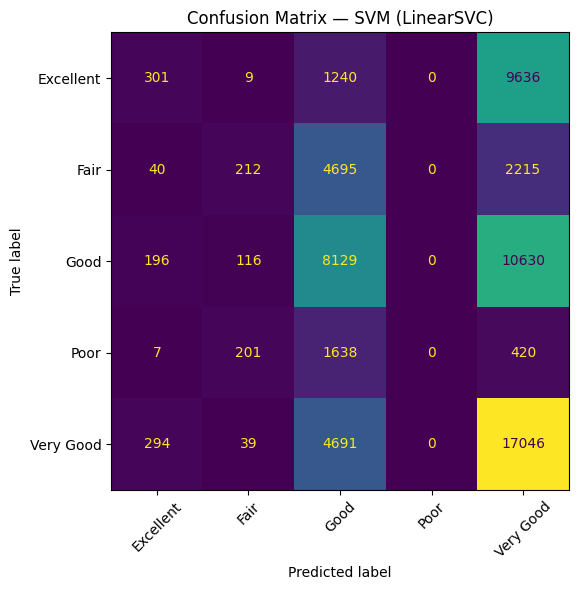

\n======================================================================
Random Forest
Accuracy: 0.4031 (40.31%)
Elapsed time: 86.6 seconds
\nClassification report:
              precision    recall  f1-score   support

   Excellent       0.39      0.23      0.29     11186
        Fair       0.33      0.17      0.23      7162
        Good       0.39      0.45      0.42     19071
        Poor       0.31      0.08      0.13      2266
   Very Good       0.43      0.56      0.49     22070

    accuracy                           0.40     61755
   macro avg       0.37      0.30      0.31     61755
weighted avg       0.39      0.40      0.39     61755



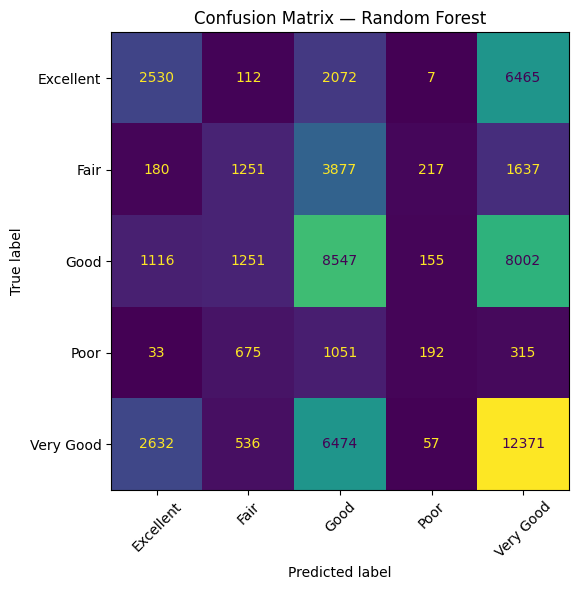

\n======================================================================
Logistic Regression
Accuracy: 0.3260 (32.60%)
Elapsed time: 17.4 seconds
\nClassification report:
              precision    recall  f1-score   support

   Excellent       0.33      0.66      0.44     11186
        Fair       0.22      0.23      0.22      7162
        Good       0.41      0.22      0.29     19071
        Poor       0.15      0.63      0.25      2266
   Very Good       0.45      0.25      0.32     22070

    accuracy                           0.33     61755
   macro avg       0.31      0.40      0.30     61755
weighted avg       0.38      0.33      0.32     61755



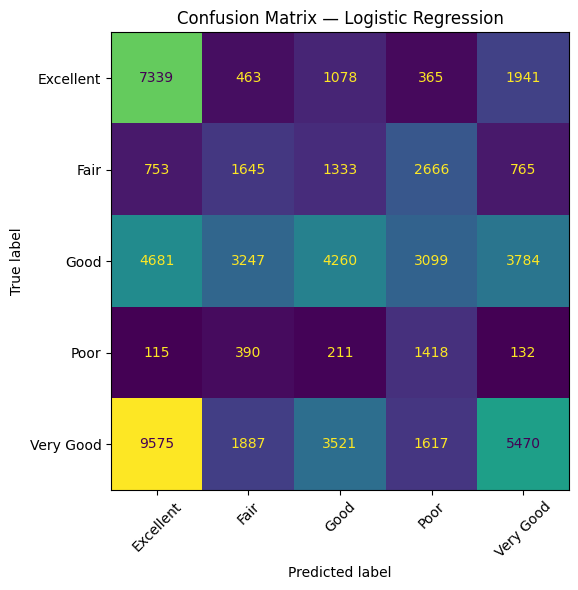

,Accuracy,Training + prediction seconds
SVM (LinearSVC),0.415966,19.330937
Random Forest,0.403060,86.613538
Logistic Regression,0.325998,17.382622


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import time

results = {}
trained_models = {}

for name, pipeline in pipelines.items():
    print("\\n" + "=" * 70)
    print(name)
    start = time.time()
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    elapsed = time.time() - start

    accuracy = accuracy_score(y_test, predictions)
    results[name] = {"Accuracy": accuracy, "Training + prediction seconds": elapsed}
    trained_models[name] = pipeline

    print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"Elapsed time: {elapsed:.1f} seconds")
    print("\\nClassification report:")
    print(classification_report(y_test, predictions, zero_division=0))

    labels = sorted(y.unique())
    cm = confusion_matrix(y_test, predictions, labels=labels)
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
        ax=ax, xticks_rotation=45, colorbar=False
    )
    ax.set_title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results).T.sort_values("Accuracy", ascending=False)
display(results_df)

## 5. Compare Model Accuracies

In this section, the test accuracy of SVM, Random Forest, and Logistic Regression is compared. A bar chart is used to visualize the results and identify which model achieved the highest accuracy on the test dataset.


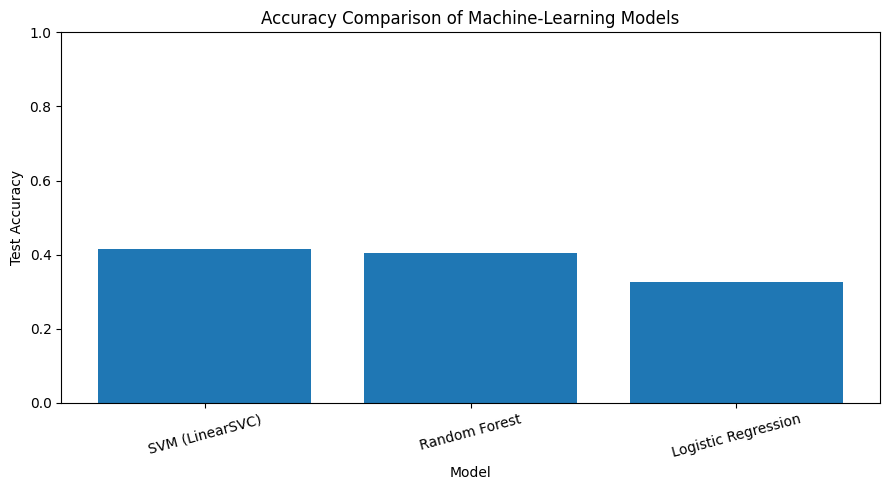

Best initial model by test accuracy: SVM (LinearSVC)
Test accuracy: 0.4160


In [ ]:
plt.figure(figsize=(9, 5))
plt.bar(results_df.index, results_df["Accuracy"])
plt.ylabel("Test Accuracy")
plt.xlabel("Model")
plt.title("Accuracy Comparison of Machine-Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

best_initial_name = results_df["Accuracy"].idxmax()
print("Best initial model by test accuracy:", best_initial_name)
print(f"Test accuracy: {results_df.loc[best_initial_name, 'Accuracy']:.4f}")

## 6. Hyperparameter Tuning Using RandomizedSearchCV

In this section, `RandomizedSearchCV` is used to find a suitable combination of hyperparameters for the Random Forest classifier. It evaluates selected parameter combinations using cross-validation and selects the best combination according to the scoring method defined in the code.

The tuned model is then evaluated on the test dataset, and its accuracy is compared with the original Random Forest model to observe whether tuning improves performance.


Fitting 3 folds for each of 6 candidates, totalling 18 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best cross-validation accuracy: 0.403
Best parameters:
{'model__max_depth': 30, 'model__max_features': 'log2', 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 155}
\nTuned Random Forest test accuracy: 0.4048
\nTuned model classification report:
              precision    recall  f1-score   support

   Excellent       0.40      0.34      0.37     11186
        Fair       0.32      0.17      0.23      7162
        Good       0.39      0.44      0.42     19071
        Poor       0.30      0.09      0.14      2266
   Very Good       0.43      0.51      0.47     22070

    accuracy                           0.40     61755
   macro avg       0.37      0.31      0.32     61755
weighted avg       0.40      0.40      0.39     61755



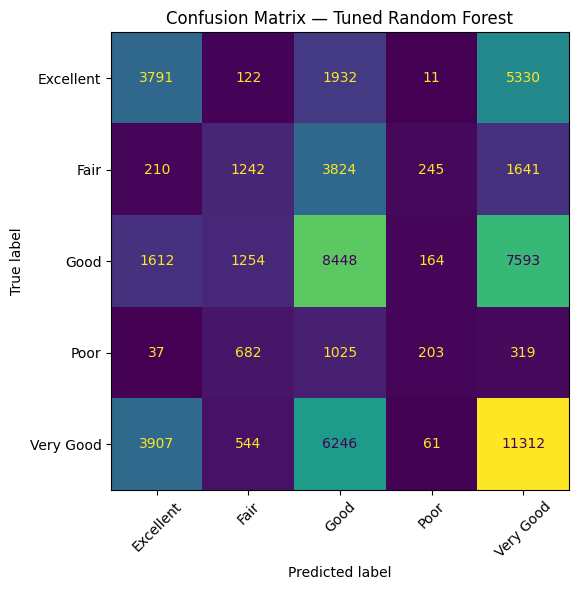

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedShuffleSplit
from scipy.stats import randint

# Use a stratified subset for the search to reduce runtime on a large dataset.
search_size = min(50000, len(X_train))
if search_size < len(X_train):
    splitter = StratifiedShuffleSplit(n_splits=1, train_size=search_size, random_state=42)
    search_indices, _ = next(splitter.split(X_train, y_train))
    X_search = X_train.iloc[search_indices]
    y_search = y_train.iloc[search_indices]
else:
    X_search, y_search = X_train, y_train

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42, n_jobs=-1, class_weight="balanced_subsample"))
])

param_distributions = {
    "model__n_estimators": randint(80, 201),
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": randint(2, 11),
    "model__min_samples_leaf": randint(1, 5),
    "model__max_features": ["sqrt", "log2"]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    scoring="accuracy",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)
random_search.fit(X_search, y_search)

print("Best cross-validation accuracy:", round(random_search.best_score_, 4))
print("Best parameters:")
print(random_search.best_params_)

# Refit the best configuration using all training data
best_rf = random_search.best_estimator_
best_rf.fit(X_train, y_train)
tuned_predictions = best_rf.predict(X_test)

print("\\nTuned Random Forest test accuracy:", round(accuracy_score(y_test, tuned_predictions), 4))
print("\\nTuned model classification report:")
print(classification_report(y_test, tuned_predictions, zero_division=0))

labels = sorted(y.unique())
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, tuned_predictions, labels=labels),
    display_labels=labels
).plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title("Confusion Matrix — Tuned Random Forest")
plt.tight_layout()
plt.show()

## 7. Single-Input General Health Prediction

In this section, a single input record is provided to the trained machine learning model. The input features are processed using the same preprocessing steps applied during model training.

The trained model predicts a general health category based on the provided input. This demonstrates how the model can be used to make an individual classification prediction.

The predicted category is an output of the machine learning model and should not be interpreted as a medical diagnosis.

In [ ]:
# Start with a valid example row so every input column is included.
single_input = X.iloc[[0]].copy()

# Optional: edit values in this dictionary. Use exact category labels from the dataset.
# Example:
# edits = {"Exercise": "Yes", "Sex": "Female", "Age_Category": "25-29", "BMI": 24.5}
edits = {}

for column, value in edits.items():
    if column not in single_input.columns:
        print(f"Skipping unknown feature: {column}")
    else:
        single_input.loc[single_input.index[0], column] = value

chosen_model = best_rf
predicted_health = chosen_model.predict(single_input)[0]

print("Input features:")
display(single_input.T.rename(columns={single_input.index[0]: "Input value"}))
print("\\nPredicted General_Health category:", predicted_health)
print("\\nReminder: this is an educational prediction and not medical advice.")

Input features:


,Input value
Checkup,Within the past 2 years
Exercise,No
Heart_Disease,No
Skin_Cancer,No
Other_Cancer,No
Depression,No
Diabetes,No
Arthritis,Yes
Sex,Female
Age_Category,70-74


\nPredicted General_Health category: Poor
\nReminder: this is an educational prediction and not medical advice.


## 8. Conclusion

In this project, I developed a machine learning classification system to predict general health categories using the `CVD_cleaned.csv` dataset. I trained and evaluated three algorithms: Support Vector Machine (SVM), Random Forest, and Logistic Regression.

The dataset was divided into 80% training data and 20% testing data. Model performance was evaluated using accuracy, classification reports, and confusion matrices. I also compared model accuracies using a bar chart and applied `RandomizedSearchCV` to tune the Random Forest model.

Among the three initial models, SVM achieved the highest test accuracy of 41.60%. The original Random Forest achieved 40.31% accuracy, while the tuned Random Forest achieved 40.48%. These results show that hyperparameter tuning produced only a small improvement in Random Forest performance.

This project helped me understand data preprocessing, model training, performance evaluation, and hyperparameter tuning.

**Disclaimer:** This project is for educational purposes only and should not be used as a substitute for professional medical advice.


